# 01 · Data cleaning

**"AI Effect" priming experiment** · Bora Şenoğlu

This notebook takes the export from Resultal (the mobile experiment tool we used to run the study) and turns it into one tidy row per participant. The statistics are in `02_statistical_analysis.ipynb`.

A quick recap of the experiment. Participants first did a short "which one do you prefer" task. This was the cover task, and it is where the prime was hidden. Depending on the condition, the last two pairs they saw were:

| Condition | What the last two pairs showed |
|---|---|
| Neutral | everyday brand logos (no technology) |
| Google control | search engine logos (Google, Bing, Yahoo, DuckDuckGo) |
| AI brand | AI company logos (ChatGPT, Gemini, Claude) |
| AI semantic | the phrases "Artificial Intelligence" and "Machine Learning", disguised as a font preference question |

After that everyone answered the same 10 questions (4 Cognitive Reflection Test items, 2 logic questions, 4 deliberately hard trivia questions), each with an "I don't know" option, and then 5 demographic questions.

The idea was that being reminded of AI might make people put in less effort: guess more, give up faster.

*A note on how this was made: the code in this notebook was written with the help of AI assistants and then reviewed and reworked. The README explains exactly where AI was used.*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

# works whether Jupyter was started in the repository root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
FIGURES = ROOT / 'figures'

## 1. Load the data

The file in `data/` is the Resultal export with the timestamps and platform IDs removed, answers sheet coded and the participant IDs replaced by codes (see `scripts/anonymize_raw_export.py`). Nothing else was changed.

In [2]:
with_defaults = pd.read_csv(DATA / 'trials_anonymized.csv')
raw = pd.read_csv(DATA / 'trials_anonymized.csv', keep_default_na=False, na_values=[''])

print('Missing responses with the pandas defaults: ', with_defaults['response'].isna().sum())
print('Missing responses when "None" is kept as text:', raw['response'].isna().sum())

raw.head(8)

Missing responses with the pandas defaults:  8
Missing responses when "None" is kept as text: 0


,participant,question_type,question_id,response,accuracy,attribute,response_time,task_id,experiment_id,time_elapsed
0,P01,NaN,8319,questions/October2026/6yYtSazNHmMUbBzfT7pX.png,NaN,right,19086,3506,AI Semantic Priming,37142
1,P01,NaN,8320,questions/October2026/GvMvQUfGoSzfZvCyjOMP.png,NaN,right,3248,3506,AI Semantic Priming,40500
2,P01,NaN,8321,questions/October2026/buX1YISiO9drWvCaQbCV.png,NaN,left,2227,3506,AI Semantic Priming,42838
3,P01,NaN,8322,questions/October2026/IKQ1kK4jgKyFbXSbaYZ1.png,NaN,left,2480,3506,AI Semantic Priming,45430
4,P01,NaN,8323,questions/October2026/rxc8tdBpNBJF73PEehNF.png,NaN,right,7804,3506,AI Semantic Priming,53346
5,P01,TRIVIA,Trivia3,I don't know,I don't know,NaN,20705,3511,AI Semantic Priming,84189
6,P01,LOGIC,Logic1,11,Wrong,NaN,37136,3511,AI Semantic Priming,121441
7,P01,CRT,CRT3,None,Correct,NaN,19309,3511,AI Semantic Priming,140866


The export is in long format: one row per response. The columns I use are

- `participant`: anonymised participant code
- `experiment_id`: the condition
- `question_type`: CRT, LOGIC or TRIVIA for the ten task questions, empty for everything else
- `question_id`: which question it was
- `response` and `accuracy`: what they answered, and whether that was Correct, Wrong or "I don't know"
- `response_time`: time spent on that question, in milliseconds
- `time_elapsed`: time since the start of the experiment, in milliseconds

## 2. Check the structure before doing anything else

Every participant should have exactly 20 rows (5 cover task choices, 10 task questions, 5 demographic questions) and belong to exactly one condition. If either of these is not true I want the notebook to stop here instead of quietly producing wrong numbers further down, which is what the `assert` lines are for.

In [3]:
rows_per_participant = raw.groupby('participant').size()
conditions_per_participant = raw.groupby('participant')['experiment_id'].nunique()

print('Rows:', len(raw))
print('Participants:', raw['participant'].nunique())
print('Rows per participant:', rows_per_participant.unique())
print('Fully duplicated rows:', raw.duplicated().sum())

assert (rows_per_participant == 20).all(), 'someone has an incomplete or doubled session'
assert (conditions_per_participant == 1).all(), 'someone appears in more than one condition'
assert raw.duplicated().sum() == 0, 'there are duplicated rows'

Rows: 780
Participants: 39
Rows per participant: [20]
Fully duplicated rows: 0


## 3. Label the three blocks


In [4]:
short_names = {
    'Neutral Condition': 'Neutral',
    'Google Effect Control': 'Google control',
    'AI Semantic Priming': 'AI semantic',
    'AI Brand Priming': 'AI brand',
}
CONDITION_ORDER = ['Neutral', 'Google control', 'AI semantic', 'AI brand']

raw = raw.rename(columns={'experiment_id': 'condition', 'attribute': 'side_chosen'})
raw['condition'] = raw['condition'].map(short_names)

demographic_questions = ['Age', 'Gender', 'Education', 'EnglishFluency', 'AIFrequency']

raw['block'] = 'cover_task'
raw.loc[raw['question_type'].notna(), 'block'] = 'task'
raw.loc[raw['question_id'].isin(demographic_questions), 'block'] = 'demographics'

# rows per condition and block (Google control has 12 participants, the others 9)
pd.crosstab(raw['condition'], raw['block']).loc[CONDITION_ORDER]

block,cover_task,demographics,task
condition,,,
Neutral,45,45,90
Google control,60,60,120
AI semantic,45,45,90
AI brand,45,45,90


In [5]:
cover = raw[raw['block'] == 'cover_task'].copy()
tasks = raw[raw['block'] == 'task'].copy()
demo = raw[raw['block'] == 'demographics'].copy()

# easier-to-use versions of the task columns
tasks['rt_s'] = tasks['response_time'] / 1000
tasks['correct'] = tasks['accuracy'] == 'Correct'
tasks['wrong'] = tasks['accuracy'] == 'Wrong'
tasks['idk'] = tasks['accuracy'] == "I don't know"

tasks[['participant', 'condition', 'question_type', 'question_id', 'response', 'accuracy', 'rt_s']].head()

,participant,condition,question_type,question_id,response,accuracy,rt_s
5,P01,AI semantic,TRIVIA,Trivia3,I don't know,I don't know,20.705
6,P01,AI semantic,LOGIC,Logic1,11,Wrong,37.136
7,P01,AI semantic,CRT,CRT3,None,Correct,19.309
8,P01,AI semantic,LOGIC,Logic2,200,Correct,52.434
9,P01,AI semantic,TRIVIA,Trivia4,I don't know,I don't know,17.437


## 4. A first look at the ten questions

Before summarising per participant I want to know whether the questions behaved the way we designed them. Trivia was supposed to be hard enough that most people would not know the answer, so that we could measure how long they waited before giving up.

In [6]:
item_summary = tasks.groupby(['question_type', 'question_id']).agg(
    correct=('correct', 'mean'),
    wrong=('wrong', 'mean'),
    idk=('idk', 'mean'),
    median_rt_s=('rt_s', 'median'),
).round(2)
item_summary

correct  wrong   idk  median_rt_s
question_type question_id                                   
CRT           CRT1            0.51   0.44  0.05        11.59
              CRT2            0.79   0.13  0.08         8.51
              CRT3            0.21   0.56  0.23        13.84
              CRT4            0.77   0.23  0.00         6.35
LOGIC         Logic1          0.59   0.28  0.13        31.26
              Logic2          0.79   0.13  0.08        19.84
TRIVIA        Trivia1         0.08   0.23  0.69         6.27
              Trivia2         0.23   0.49  0.28         8.46
              Trivia3         0.26   0.23  0.51         8.62
              Trivia4         0.15   0.13  0.72         9.51

That looks right. Trivia has by far the most "I don't know" answers, and CRT3 is the item where the intuitive answer catches most people.

Since the response column still has the actual answers, I can also mark the CRT **lure** answers. CRT items are built so that one specific wrong answer pops into your head first. Giving that answer means System 1 won, which is more informative for our research question than just "wrong". The lure key below is based on the four CRT-2 items (Thomson & Oppenheimer, 2016).

In [7]:
crt_lures = {'CRT1': '7', 'CRT2': 'June', 'CRT3': '27', 'CRT4': 'First'}

# for non-CRT questions .map() gives NaN, so the comparison is simply False
tasks['lure'] = tasks['response'] == tasks['question_id'].map(crt_lures)

crt = tasks[tasks['question_type'] == 'CRT']
print('Share of wrong CRT answers that were the intuitive lure: {:.0%}'.format(
    crt['lure'].sum() / crt['wrong'].sum()))

Share of wrong CRT answers that were the intuitive lure: 89%


## 5. Response times

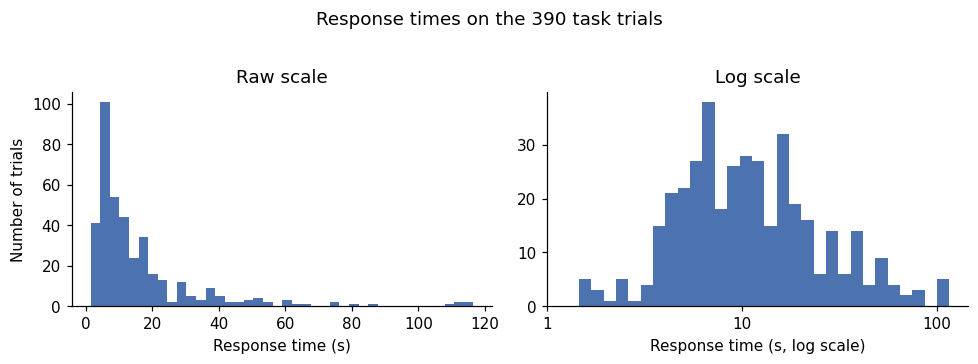

count    390.0
mean      16.1
std       17.8
min        1.5
25%        6.2
50%       10.1
75%       18.2
max      116.5
Name: rt_s, dtype: float64


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))

axes[0].hist(tasks['rt_s'], bins=40, color='#4c72b0')
axes[0].set_xlabel('Response time (s)')
axes[0].set_ylabel('Number of trials')
axes[0].set_title('Raw scale')

axes[1].hist(np.log10(tasks['rt_s']), bins=30, color='#4c72b0')
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(['1', '10', '100'])
axes[1].set_xlabel('Response time (s, log scale)')
axes[1].set_title('Log scale')

fig.suptitle('Response times on the 390 task trials', y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / '01_response_time_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(tasks['rt_s'].describe().round(1))

Response times are strongly right-skewed, which is normal for this kind of data. Most answers take around 10 seconds, a few take almost two minutes.

In my first version I made a boxplot of each participant's *mean* response time, saw one point sticking out in the Neutral group, and removed that participant by typing in their ID. Looking at it again, I do not think that was a good decision, and the table below shows why.

In [9]:
long_trials = tasks.loc[tasks['rt_s'] > 100,
                        ['participant', 'condition', 'question_id', 'rt_s', 'accuracy']]
long_trials.sort_values('rt_s', ascending=False)

,participant,condition,question_id,rt_s,accuracy
731,P37,AI brand,Logic1,116.534,Correct
226,P12,AI brand,Logic1,115.167,Wrong
409,P21,AI semantic,Logic1,112.975,Correct
213,P11,Neutral,Logic2,112.424,Correct
513,P26,Google control,Logic2,109.104,Correct


Five participants each have one trial of more than 100 seconds. I only removed one of them, the one who happened to be in the group with the least spread, so my rule was not consistent. And all five long trials are logic questions, four of them answered correctly. That does not look like noise. It looks like people sitting down and working the problem out (or getting distracted, or looking it up, I cannot tell from the data). Either way, persistence is exactly what the experiment is about, so deleting the people who showed the most of it would be a strange thing to do.

So instead of removing anyone because of one slow trial, I summarise each participant with their **median** response time. One very long trial barely moves a median. I still compute the mean as well, because that is what the paper reported, and I want to be able to compare.

## 6. Did everyone actually do the task?

There is a different kind of problem that I did not check for the first time: people who tap through without reading. The cover task is useful here. If someone "chooses" between two logos in a fraction of a second, they did not really look at them, which means they were not really exposed to the prime.

In [10]:
quality = tasks.groupby('participant').agg(
    condition=('condition', 'first'),
    task_median_rt_s=('rt_s', 'median'),
    prop_correct=('correct', 'mean'),
)
quality['cover_median_rt_s'] = cover.groupby('participant')['response_time'].median() / 1000
quality['total_duration_s'] = raw.groupby('participant')['time_elapsed'].max() / 1000

# less than half a second per logo pair = tapping through the cover task
CLICK_THROUGH_CUTOFF_S = 0.5
quality['flag_clickthrough'] = quality['cover_median_rt_s'] < CLICK_THROUGH_CUTOFF_S

quality.sort_values('cover_median_rt_s').head(6).round(2)

,condition,task_median_rt_s,prop_correct,cover_median_rt_s,total_duration_s,flag_clickthrough
participant,,,,,,
P10,Google control,3.37,0.8,0.17,63.63,True
P22,AI brand,1.72,0.9,0.21,39.78,True
P09,Google control,4.20,0.8,0.85,108.61,False
P34,Google control,4.33,0.4,0.94,183.91,False
P30,Neutral,6.99,0.4,1.09,150.17,False
P32,Neutral,11.54,0.5,1.34,247.15,False


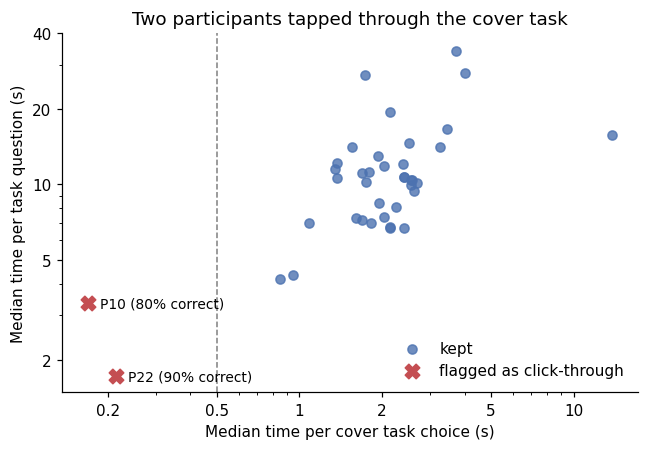

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.2))

ok = quality[~quality['flag_clickthrough']]
flagged = quality[quality['flag_clickthrough']]

ax.scatter(ok['cover_median_rt_s'], ok['task_median_rt_s'],
           color='#4c72b0', alpha=0.8, label='kept')
ax.scatter(flagged['cover_median_rt_s'], flagged['task_median_rt_s'],
           color='#c44e52', marker='X', s=90, label='flagged as click-through')
for code, row in flagged.iterrows():
    ax.annotate('{} ({:.0%} correct)'.format(code, row['prop_correct']),
                (row['cover_median_rt_s'], row['task_median_rt_s']),
                xytext=(8, -3), textcoords='offset points', fontsize=9)

ax.axvline(CLICK_THROUGH_CUTOFF_S, color='grey', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10])
ax.set_xticklabels(['0.2', '0.5', '1', '2', '5', '10'])
ax.set_yticks([2, 5, 10, 20, 40])
ax.set_yticklabels(['2', '5', '10', '20', '40'])
ax.set_xlabel('Median time per cover task choice (s)')
ax.set_ylabel('Median time per task question (s)')
ax.set_title('Two participants tapped through the cover task')
ax.legend(frameon=False, loc='lower right')

fig.tight_layout()
fig.savefig(FIGURES / '02_click_through_check.png', dpi=150, bbox_inches='tight')
plt.show()

Two participants stand apart from everyone else. They spent about 0.2 seconds per logo pair (the next fastest person took 0.85 seconds), finished the whole experiment in about a minute when the typical participant needed almost four, and still got 80 to 90% of the questions right, including trivia that nearly everybody else gave up on. My best guess is that they had seen the questions before, for example as a test run or a second attempt, but I cannot know that.

What I can say is that they did not look at the prime, so they cannot tell us anything about priming. I flag them here and leave them out of the main analysis in notebook 02. I do not delete them from the file. Notebook 02 also reports what happens when they stay in, so anyone can see how much this decision matters.

To be honest about it: this rule was made after seeing the data.

## 7. One row per participant

In [12]:
# accuracy and response time
per_participant = tasks.groupby('participant').agg(
    condition=('condition', 'first'),
    n_trials=('question_id', 'size'),
    prop_correct=('correct', 'mean'),
    prop_wrong=('wrong', 'mean'),
    prop_idk=('idk', 'mean'),
    median_rt_s=('rt_s', 'median'),
    mean_rt_s=('rt_s', 'mean'),
)

# of the questions they attempted (did not answer "I don't know"), how many were right?
per_participant['acc_when_attempted'] = (
    per_participant['prop_correct'] / (per_participant['prop_correct'] + per_participant['prop_wrong'])
)

# give-up time: how long they waited before choosing "I don't know"
give_up = tasks[tasks['idk']].groupby('participant').agg(
    n_idk=('rt_s', 'size'),
    giveup_median_s=('rt_s', 'median'),
    giveup_mean_s=('rt_s', 'mean'),
)

# the same accuracy measures split by question type (crt_correct, trivia_wrong, ...)
by_type = tasks.pivot_table(index='participant', columns='question_type',
                            values=['correct', 'wrong', 'idk'], aggfunc='mean')
by_type.columns = ['{}_{}'.format(qtype.lower(), outcome) for outcome, qtype in by_type.columns]

# share of CRT items answered with the intuitive lure
crt_lure_rate = crt.groupby('participant')['lure'].mean().rename('crt_lure_rate')

per_participant = per_participant.join(give_up).join(by_type).join(crt_lure_rate)
per_participant['n_idk'] = per_participant['n_idk'].fillna(0).astype(int)

per_participant.head()

,condition,n_trials,prop_correct,prop_wrong,prop_idk,median_rt_s,mean_rt_s,acc_when_attempted,n_idk,giveup_median_s,giveup_mean_s,crt_correct,logic_correct,trivia_correct,crt_idk,logic_idk,trivia_idk,crt_wrong,logic_wrong,trivia_wrong,crt_lure_rate
participant,,,,,,,,,,,,,,,,,,,,,
P01,AI semantic,10,0.2,0.3,0.5,14.0880,18.5919,0.400000,5,7.632,11.518600,0.25,0.5,0.00,0.25,0.0,1.00,0.50,0.5,0.00,0.50
P02,Google control,10,0.6,0.1,0.3,15.7160,18.6583,0.857143,3,15.253,12.706333,1.00,1.0,0.00,0.00,0.0,0.75,0.00,0.0,0.25,0.00
P03,AI semantic,10,0.6,0.1,0.3,16.5330,23.8495,0.857143,3,13.228,29.687667,0.75,1.0,0.25,0.00,0.0,0.75,0.25,0.0,0.00,0.25
P04,Neutral,10,0.7,0.2,0.1,6.6830,7.5992,0.777778,1,6.707,6.707000,0.75,1.0,0.50,0.00,0.0,0.25,0.25,0.0,0.25,0.25
P05,Neutral,10,0.2,0.3,0.5,7.1745,11.5941,0.400000,5,6.323,11.141400,0.50,0.0,0.00,0.25,0.5,0.75,0.25,0.5,0.25,0.25


A note on give-up time: three participants never chose "I don't know", so they have no give-up time and will be missing from that one analysis. And for many participants it is based on only one or two trials (see `n_idk`), so it is a noisy measure.

Now the demographics.

In [13]:
demographics = demo.pivot(index='participant', columns='question_id', values='response')
demographics = demographics.rename(columns={
    'Age': 'age',
    'Gender': 'gender',
    'Education': 'education',
    'EnglishFluency': 'english',
    'AIFrequency': 'ai_use',
})

# shorter labels
demographics['education'] = demographics['education'].replace({
    'High School / Secondary Education': 'High school',
    'Bachelor’s Degree (or equivalent)': 'Bachelor',
    'Master’s Degree (or equivalent)': 'Master',
})
demographics['english'] = demographics['english'].replace({
    'Beginner proficiency (A1-A2)': 'A1-A2',
    'Intermediate proficiency (B1-B2)': 'B1-B2',
    'Fluent / Advanced proficiency (C1-C2)': 'C1-C2',
    'Native / Bilingual proficiency': 'Native',
})

# the two variables I want to use in the analysis, in a form that is easy to model
demographics['english_high'] = demographics['english'].isin(['C1-C2', 'Native'])
demographics['ai_use_num'] = demographics['ai_use'].map({
    'Rarely or Never': 1,
    'A few times a month': 2,
    'A few times a week': 3,
    'Daily': 4,
})

demographics = demographics[['age', 'gender', 'education', 'english', 'english_high', 'ai_use', 'ai_use_num']]

for column in ['age', 'gender', 'education', 'english', 'ai_use']:
    print(demographics[column].value_counts().to_string(), '\n')

age
18-24                29
25-34                 8
Prefer not to say     2 

gender
Male                 18
Female               18
Non-binary            2
Prefer not to say     1 

education
Bachelor             29
High school           4
Master                3
Prefer not to say     3 

english
C1-C2     24
Native     7
B1-B2      5
A1-A2      3 

ai_use
A few times a week     16
Daily                  13
Rarely or Never         7
A few times a month     3 



In [ ]:
quality_columns = ['cover_median_rt_s', 'total_duration_s', 'flag_clickthrough']

participants = per_participant.join(demographics).join(quality[quality_columns])
participants.head()

,condition,n_trials,prop_correct,prop_wrong,prop_idk,median_rt_s,mean_rt_s,acc_when_attempted,n_idk,giveup_median_s,giveup_mean_s,crt_correct,logic_correct,trivia_correct,crt_idk,logic_idk,trivia_idk,crt_wrong,logic_wrong,trivia_wrong,crt_lure_rate,age,gender,education,english,english_high,ai_use,ai_use_num,cover_median_rt_s,total_duration_s,flag_clickthrough
participant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P01,AI semantic,10,0.2,0.3,0.5,14.0880,18.5919,0.400000,5,7.632,11.518600,0.25,0.5,0.00,0.25,0.0,1.00,0.50,0.5,0.00,0.50,25-34,Male,Master,C1-C2,True,A few times a week,3,3.248,308.259,False
P02,Google control,10,0.6,0.1,0.3,15.7160,18.6583,0.857143,3,15.253,12.706333,1.00,1.0,0.00,0.00,0.0,0.75,0.00,0.0,0.25,0.00,25-34,Male,High school,Native,True,Rarely or Never,1,13.764,787.734,False
P03,AI semantic,10,0.6,0.1,0.3,16.5330,23.8495,0.857143,3,13.228,29.687667,0.75,1.0,0.25,0.00,0.0,0.75,0.25,0.0,0.00,0.25,18-24,Female,Bachelor,C1-C2,True,A few times a week,3,3.449,300.720,False
P04,Neutral,10,0.7,0.2,0.1,6.6830,7.5992,0.777778,1,6.707,6.707000,0.75,1.0,0.50,0.00,0.0,0.25,0.25,0.0,0.25,0.25,25-34,Male,Bachelor,C1-C2,True,Daily,4,2.411,163.987,False
P05,Neutral,10,0.2,0.3,0.5,7.1745,11.5941,0.400000,5,6.323,11.141400,0.50,0.0,0.00,0.25,0.5,0.75,0.25,0.5,0.25,0.25,18-24,Female,Bachelor,C1-C2,True,Rarely or Never,1,1.691,180.860,False


## 8. Sanity checks

Three quick checks on the final table.

In [15]:
proportion_sum = participants[['prop_correct', 'prop_wrong', 'prop_idk']].sum(axis=1)

assert len(participants) == 39
assert (participants['n_trials'] == 10).all()
assert np.allclose(proportion_sum, 1), 'Correct + Wrong + IDK should add up to 1'
assert participants['ai_use_num'].notna().all(), 'an AI use answer was not mapped'

print('All checks passed.\n')
print(participants['condition'].value_counts().loc[CONDITION_ORDER].to_string())

All checks passed.

condition
Neutral            9
Google control    12
AI semantic        9
AI brand           9


In [16]:
# Table 1 of the paper: all 39 participants, mean response times
paper_table = participants.groupby('condition')[
    ['prop_correct', 'prop_idk', 'prop_wrong', 'mean_rt_s', 'giveup_mean_s']
].mean().loc[CONDITION_ORDER]

paper_table.round(3)

,prop_correct,prop_idk,prop_wrong,mean_rt_s,giveup_mean_s
condition,,,,,
Neutral,0.411,0.333,0.256,13.944,10.362
Google control,0.525,0.242,0.233,14.258,9.749
AI semantic,0.422,0.344,0.233,21.700,17.995
AI brand,0.367,0.200,0.433,15.118,8.181




## 9. Save

In [17]:
participants.to_csv(DATA / 'participants_clean.csv')

print('Saved {} participants, {} columns.'.format(*participants.shape))
print('Flagged as click-through:', list(participants.index[participants['flag_clickthrough']]))

Saved 39 participants, 31 columns.
Flagged as click-through: ['P10', 'P22']


## What changed compared to my first version

| | First version | This version |
|---|---|---|
| "None" answers | read as missing without me noticing | read as text |
| Finding the demographic rows | dictionary of every possible answer | `question_id` |
| "Prefer not to say" | silently dropped | kept |
| Slow participant | one person removed by ID, after looking at a boxplot | nobody removed, median response time instead of mean |
| Click-through participants | not checked | flagged with a written rule, kept in the file |
| Actual answers | deleted | used to score CRT lure answers |
| Checks | by eye | `assert` statements and a comparison with the paper |